In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sheets = pd.read_excel("online_retail_II.xlsx", sheet_name=None)
df = pd.concat(sheets.values(), ignore_index=True)

In [3]:
print("Shape:", df.shape)

Shape: (1067371, 8)


In [4]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB


In [6]:
df.isna().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [7]:
cancelled = df[df['Invoice'].astype(str).str.startswith('C')]
print("Cancelled orders:", cancelled.shape[0])

print("Negative/zero Quantity:", (df['Quantity'] <= 0).sum())

print("Negative/zero Price:", (df['Price'] <= 0).sum())

Cancelled orders: 19494
Negative/zero Quantity: 22950
Negative/zero Price: 6207


In [8]:
cancelled_orders = df[df['Invoice'].astype(str).str.startswith('C')].copy()

df_clean = df[~df['Invoice'].astype(str).str.startswith('C')].copy()

df_clean = df_clean.dropna(subset=['Customer ID'])

df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['Price'] > 0)]

df_clean['Customer ID'] = df_clean['Customer ID'].astype(int)

print("Original shape:", df.shape)
print("Cancelled orders shape:", cancelled_orders.shape)
print("Clean data shape:", df_clean.shape)

Original shape: (1067371, 8)
Cancelled orders shape: (19494, 8)
Clean data shape: (805549, 8)


In [9]:
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['Price']
df_clean.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [10]:
reference_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print("Reference date:", reference_date)

Reference date: 2011-12-10 12:50:00


In [11]:
rfm = df_clean.groupby('Customer ID').agg(
    Recency = ('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency = ('Invoice', 'nunique'),
    Monetary = ('TotalPrice', 'sum')
).reset_index()

print(rfm.shape)
rfm.head()

(5878, 4)


,Customer ID,Recency,Frequency,Monetary
0,12346,326,12,77556.46
1,12347,2,8,5633.32
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40


In [12]:
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1])

rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5])

rfm['R_Score'] = rfm['R_Score'].astype(int)
rfm['F_Score'] = rfm['F_Score'].astype(int)
rfm['M_Score'] = rfm['M_Score'].astype(int)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346,326,12,77556.46,2,5,5
1,12347,2,8,5633.32,5,4,5
2,12348,75,5,2019.40,3,4,4
3,12349,19,4,4428.69,5,3,5
4,12350,310,1,334.40,2,1,2


In [15]:
rfm['RFM_Score'] = rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']

def segment_customer_v2(row):
    R, F, M = row['R_Score'], row['F_Score'], row['M_Score']
    total = row['RFM_Score']
    
    if R <= 2 and F <= 2:
        return 'Lost / Churned'
    elif R <= 2 and F >= 3:
        return 'At-risk / Churning'
    elif F >= 4 and M <= 2:
        return 'Discount-seeker'
    elif total >= 12:
        return 'Loyal'
    elif R >= 4 and total <= 9:
        return 'New customer'
    else:
        return 'Potential Loyalist'

rfm['Segment'] = rfm.apply(segment_customer_v2, axis=1)
print(rfm['Segment'].value_counts())

Segment
Loyal                 1686
Lost / Churned        1523
Potential Loyalist    1307
At-risk / Churning     824
New customer           484
Discount-seeker         54
Name: count, dtype: int64


In [16]:
print(rfm.groupby('M_Score')['Monetary'].agg(['min', 'max', 'mean']))
print()

print(rfm.groupby('F_Score')['Frequency'].agg(['min', 'max', 'mean']))
print()

print(rfm.groupby('R_Score')['Recency'].agg(['min', 'max', 'mean']))

             min        max          mean
M_Score                                  
1           2.95     291.13    164.446905
2         291.50     618.09    430.286648
3         618.27    1248.42    904.136159
4        1249.01    2957.47   1934.266062
5        2972.83  608821.65  11656.824882

         min  max       mean
F_Score                     
1          1    1   1.000000
2          1    2   1.619574
3          2    4   3.068027
4          4    8   5.768511
5          8  398  19.986395

         min  max        mean
R_Score                      
1        411  739  544.199149
2        190  410  310.742321
3         60  189  108.172237
4         20   59   36.405612
5          1   19    9.053030


In [17]:
order_value = df_clean.groupby('Invoice')['TotalPrice'].sum()
overall_aov = order_value.mean()
print("Overall AOV: £", round(overall_aov, 2))

Overall AOV: £ 479.95


In [18]:
rfm['CLV'] = rfm['Monetary']

segment_summary = rfm.groupby('Segment').agg(
    Customers = ('Customer ID', 'count'),
    Avg_Recency = ('Recency', 'mean'),
    Avg_Frequency = ('Frequency', 'mean'),
    Avg_Monetary_CLV = ('Monetary', 'mean'),
    Total_Revenue = ('Monetary', 'sum')
).reset_index()

segment_summary['Revenue_Share_%'] = (segment_summary['Total_Revenue'] / segment_summary['Total_Revenue'].sum() * 100).round(2)
segment_summary = segment_summary.sort_values('Total_Revenue', ascending=False)
print(segment_summary)

              Segment  Customers  Avg_Recency  Avg_Frequency  \
3               Loyal       1686    30.304864      15.251483   
0  At-risk / Churning        824   369.100728       4.940534   
5  Potential Loyalist       1307    84.104055       3.213466   
2      Lost / Churned       1523   459.281024       1.252791   
4        New customer        484    30.522727       1.657025   
1     Discount-seeker         54    74.333333       5.074074   

   Avg_Monetary_CLV  Total_Revenue  Revenue_Share_%  
3       8219.727686   1.385846e+07            78.10  
0       1982.979966   1.633975e+06             9.21  
5       1047.255627   1.368763e+06             7.71  
2        438.031466   6.671219e+05             3.76  
4        392.639215   1.900374e+05             1.07  
1        464.266667   2.507040e+04             0.14  


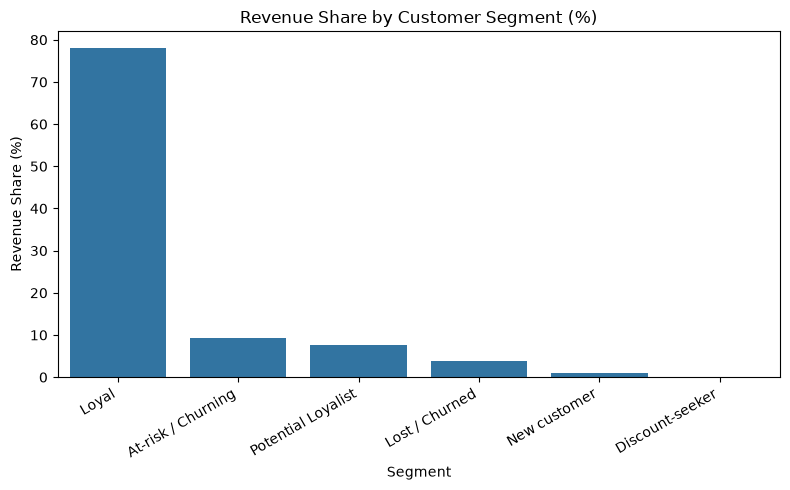

In [19]:
plt.figure(figsize=(8,5))
sns.barplot(data=segment_summary, x='Segment', y='Revenue_Share_%', order=segment_summary.sort_values('Revenue_Share_%', ascending=False)['Segment'])
plt.xticks(rotation=30, ha='right')
plt.title('Revenue Share by Customer Segment (%)')
plt.ylabel('Revenue Share (%)')
plt.tight_layout()
plt.show()

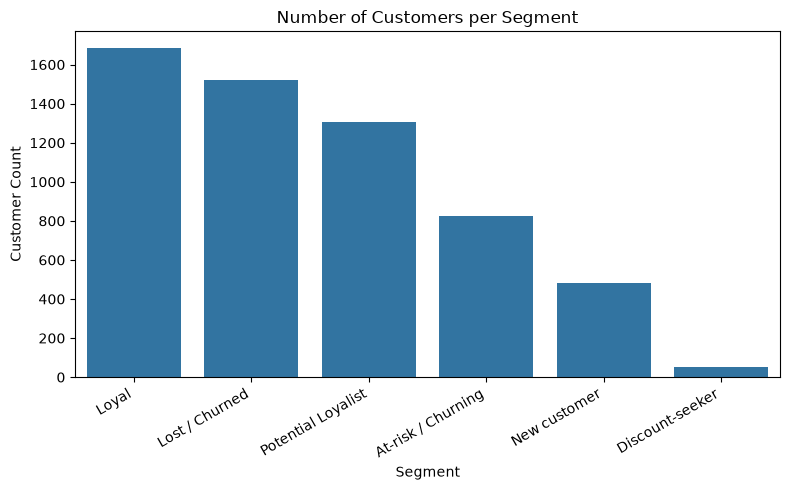

In [20]:
plt.figure(figsize=(8,5))
sns.barplot(data=segment_summary, x='Segment', y='Customers', order=segment_summary.sort_values('Customers', ascending=False)['Segment'])
plt.xticks(rotation=30, ha='right')
plt.title('Number of Customers per Segment')
plt.ylabel('Customer Count')
plt.tight_layout()
plt.show()

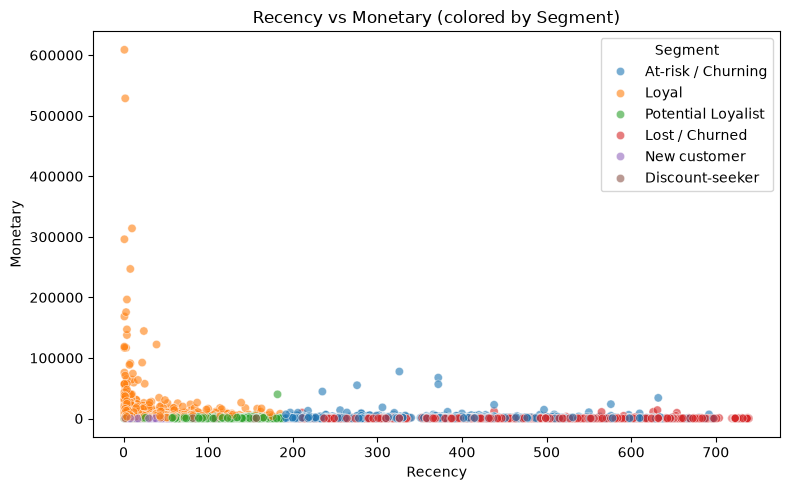

In [21]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Segment', alpha=0.6)
plt.title('Recency vs Monetary (colored by Segment)')
plt.tight_layout()
plt.show()

## Business Insights & Recommendations

**Key Finding:** Just 29% of customers (the "Loyal" segment) generate 78% of total revenue — a 
classic Pareto (80/20) pattern. The business should prioritize retaining Loyal customers and 
winning back At-risk customers, since retaining an existing high-value customer is significantly 
cheaper than acquiring a new one.

| Segment | What the Data Shows | Recommended Action |
|---|---|---|
| **Loyal** (1,686 customers, 29% — contribute 78% of revenue) | Core revenue drivers of the business | Protect at all costs. Offer loyalty perks, early access to new products, and personalized appreciation. Minimal extra marketing spend needed — focus on retention, not acquisition |
| **At-risk / Churning** (824 customers, avg. CLV £1,983, inactive ~369 days) | Previously high-value customers who are going inactive | Highest priority for action. Launch targeted win-back campaigns (personalized discounts, "we miss you" emails). Recovering these customers is more cost-effective than acquiring new ones |
| **Lost / Churned** (1,523 customers, only 3.76% of revenue) | Large in number but historically low value | Low-cost win-back attempts (bulk email) are reasonable, but avoid heavy investment — redirect resources toward Loyal and At-risk segments |
| **Discount-seeker** (54 customers, 0.14% of revenue) | Frequent but very low-value purchases | Negligible business impact; a dedicated strategy is not worth the effort |
| **New Customer** (484 customers) | Too early to evaluate long-term value | Focus on onboarding — welcome offers and incentives for a second purchase to push conversion into the Loyal segment |
| **Potential Loyalist** (1,307 customers, 7.71% of revenue) | Mid-tier customers with upside potential | Targeted incentives (discounts, reminders) to nudge them toward becoming Loyal customers |

### Summary
Revenue is heavily concentrated in a small customer base. Retention strategy for Loyal and 
At-risk segments should be the top business priority, while low-value segments (Lost, 
Discount-seeker) require minimal investment.

In [22]:
rfm.to_csv("rfm_segments.csv", index=False)

segment_summary.to_csv("segment_summary.csv", index=False)

df_clean.to_csv("clean_transactions.csv", index=False)

print("Files saved successfully")

Files saved successfully
